# Basic Usage


This notebook demonstrates how to use the custom experimentalist sample_flavour and compares it to random sampling in a closed-loop model discovery process using AutoRA.

`sample_flavour` is a **proximity-aware sampler** that chooses new candidate data points by **favoring those close to existing ones**, optionally softened by a `temperature` parameter. It supports:

* **Inverse-distance weighting**
* **Gaussian kernel proximity**

It's a basic **active learning strategy** where proximity is used to bias sampling.

here is a brief Introduction on how to use it:

Example Use Case

Imagine you're doing an experiment with temperature and pressure:

You’ve already tested 5 conditions (conditions)

You generate 100 new potential test points (candidates)

You want to choose 3 that are near your known data, but still explore a bit

Call:

In [1]:
import sys
import os
import numpy as np

# Step 1: Add path to your experimentalist module
src_path = os.path.abspath(os.path.join('..', 'src'))  # adjust if your path differs
sys.path.append(src_path)

# Step 2: Import your experimentalist
from autora.experimentalist.autora_experimentalist_example import sample_flavour

# Step 3: Existing experimental data (e.g., from 5 prior experiments)
conditions = np.array([
    [0.1, 0.4],
    [0.2, 0.5],
    [0.3, 0.6],
    [0.4, 0.7],
    [0.5, 0.8],
])

# Step 4: Candidate pool (e.g., 100 new experiments to choose from)
# Imagine this is a grid or randomly generated across your input space
candidates = np.random.rand(100, 2)  # 2D space: [temperature, pressure]

# Step 5: Sample 3 new informative conditions
selected_conditions = sample_flavour(
    conditions=conditions,        # your existing data
    candidates=candidates,        # pool to select from
    sampler="gaussian",           # sampling strategy (e.g., gaussian proximity)
    num_samples=3,                # how many to select
    temperature=0.5,              # exploration-exploitation balance
    sigma=0.2                     # width of gaussian kernel
)

# Step 6: Output
print("Selected new conditions:")
print(selected_conditions)


Selected new conditions:
[[0.49394156 0.6483588 ]
 [0.33703039 0.6053681 ]
 [0.1488661  0.62356965]]


This selects 3 new candidates based on Gaussian proximity to existing points, with a moderate level of randomness (temperature=0.5).

# Benchmarking

Now we will demonstrate how to benchmark a **custom experimentalist** (`sample_flavour`) against **random sampling**, using a **closed-loop discovery process** powered by [AutoRA](https://github.com/AutoResearch/autora).

We'll simulate model discovery for two synthetic ground-truth domains:
- Task Switching (Neuroscience)
- Expected Value Theory (Economics)

We compare how quickly each method reduces validation error over time.

In [2]:
# autora state
from autora.state import State, StandardState, on_state, estimator_on_state, Delta, VariableCollection

# experiment_runner
from autora.experiment_runner.synthetic.psychology.luce_choice_ratio import luce_choice_ratio
from autora.experiment_runner.synthetic.psychology.exp_learning import exp_learning
from autora.experiment_runner.synthetic.economics.expected_value_theory import expected_value_theory

# experiment_runner
from autora.experiment_runner.synthetic.neuroscience.task_switching import task_switching

# experimentalist
from autora.experimentalist.grid import grid_pool
from autora.experimentalist.random import random_pool, random_sample
from autora.experimentalist.falsification import falsification_sample
from autora.experimentalist.model_disagreement import model_disagreement_sample
from autora.experimentalist.uncertainty import uncertainty_sample

# theorist
from autora.theorist.bms import BMSRegressor

# sklearn
from sklearn.base import BaseEstimator
from sklearn.model_selection import train_test_split
from sklearn import linear_model

# general
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass, field
from typing import Optional, List


In [3]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

class PolynomialRegressor:
    """
    This theorist fits a polynomial function to the data.
    """

    def __init__(self, degree: int = 3):
      self.poly = PolynomialFeatures(degree=degree, include_bias=False)
      self.model = LinearRegression()

    def fit(self, x, y):
      features = self.poly.fit_transform(x, y)
      self.model.fit(features, y)
      return self

    def predict(self, x):
      features = self.poly.fit_transform(x)
      return self.model.predict(features)

    def print_eqn(self):
        # Extract the coefficients and intercept
        coeffs = self.model.coef_
        intercept = self.model.intercept_

        # Handle multi-output case by iterating over each output's coefficients and intercept
        if coeffs.ndim > 1:
            for idx in range(coeffs.shape[0]):
                equation = f"y{idx+1} = {intercept[idx]:.3f}"
                feature_names = self.poly.get_feature_names_out()
                for coef, feature in zip(coeffs[idx], feature_names):
                    equation += f" + ({coef:.3f}) * {feature}"
                print(equation)
        else:
            equation = f"y = {intercept:.3f}"
            feature_names = self.poly.get_feature_names_out()
            for coef, feature in zip(coeffs, feature_names):
                equation += f" + ({coef:.3f}) * {feature}"
            print(equation)



In [4]:
# SET UP STATE
# Here, we use a non-standard State to be able to use a multiple models
@dataclass(frozen=True)
class CustomState(State):
    variables: Optional[VariableCollection] = field(
        default=None, metadata={"delta": "replace"}
    )
    conditions: Optional[pd.DataFrame] = field(
        default=None, metadata={"delta": "replace", "converter": pd.DataFrame}
    )
    experiment_data: Optional[pd.DataFrame] = field(
        default=None, metadata={"delta": "extend", "converter": pd.DataFrame}
    )
    models_bms: List[BaseEstimator] = field(
        default_factory=list,
        metadata={"delta": "extend"},
    )
    models_lr: List[BaseEstimator] = field(
        default_factory=list,
        metadata={"delta": "extend"},
    )
    models_polyr: List[BaseEstimator] = field(
        default_factory=list,
        metadata={"delta": "extend"},
    )

In [5]:
# state wrapper for all theorists
@on_state()
def theorists_on_state(experiment_data, variables, bms_epochs):

  # extract conditions X and observations y from experiment data
  ivs = [iv.name for iv in variables.independent_variables]
  dvs = [dv.name for dv in variables.dependent_variables]
  X = experiment_data[ivs]
  y = experiment_data[dvs]

  # initialize and fit theorists
  theorist_bms = BMSRegressor(epochs=bms_epochs)
  theorist_polyr = PolynomialRegressor()
  theorist_lr = linear_model.LinearRegression()

  return Delta(models_bms = [theorist_bms.fit(X, y)],
               models_lr=[theorist_lr.fit(X, y)],
               models_polyr=[theorist_polyr.fit(X, y)])

In [6]:
# state wrapper for grid pooler experimentalist (generates a grid of experiment conditions)
import sys
import os

# Get the absolute path to the src/ folder
src_path = os.path.abspath(os.path.join('..', 'src'))
sys.path.append(src_path)

from autora.experimentalist.autora_experimentalist_example import sample_flavour


@on_state()
def grid_pool_on_state(variables):
  return Delta(conditions=grid_pool(variables))

# state wrapper for random pooler experimentalist (generates a pool of experiment conditions)
@on_state()
def random_pool_on_state(variables, num_samples, random_state=None):
  return Delta(conditions=random_pool(variables, num_samples, random_state))

# state wrapper for random experimentalist (samples experiment conditions from a set of conditions)
@on_state()
def random_sample_on_state(conditions, all_conditions, num_samples, random_state=None):
  return Delta(conditions=random_sample(all_conditions, num_samples, random_state))

# **** STATE WRAPPER FOR YOUR EXPERIMENTALIST ***
@on_state()
def custom_sample_on_state(experiment_data,
                           models_bms,
                           models_lr,
                           models_polyr,
                           all_conditions,
                           num_samples=1,
                           random_state=None):

  # this is just an example where we integrate the model diagreement sampler
  # into the wrapper
 

  conditions = sample_flavour(
    conditions = experiment_data.iloc[:, 1:].values,
    candidates = all_conditions.values,
    temperature=5,
    num_samples = num_samples,
    sampler= "gaussian"
  )


  #conditions = model_disagreement_sample(
   #       all_conditions,
    #      models = [models_bms[-1], models_lr[-1]],
     #     num_samples = num_samples
      #)

  return Delta(conditions=conditions)

In [7]:
# state wrapper for synthetic experiment runner
@on_state()
def run_experiment_on_state(conditions, experiment_runner):
  data = experiment_runner.run(conditions=conditions, added_noise=0.0)
  return Delta(experiment_data=data)

In [8]:
# the following function is used to compute the model performance
# on the validation set in terms of mean squared error
def get_validation_MSE(validation_experiment_data, working_state):
    ivs = [iv.name for iv in validation_experiment_data.variables.independent_variables]
    dvs = [dv.name for dv in validation_experiment_data.variables.dependent_variables]
    X = validation_experiment_data.experiment_data[ivs]
    y = validation_experiment_data.experiment_data[dvs]

    y_pred_bms = working_state.models_bms[-1].predict(X)
    y_pred_lr = working_state.models_lr[-1].predict(X)
    y_pred_polyr = working_state.models_polyr[-1].predict(X)

    MSE_bms = ((y - y_pred_bms)**2).mean()[0]
    MSE_lr = ((y - y_pred_lr)**2).mean()[0]
    MSE_polyr = ((y - y_pred_polyr)**2).mean()[0]

    min_MSE = min(MSE_bms, MSE_lr, MSE_polyr)

    return min_MSE

In [9]:
def run_simulation(num_cycles, num_conditions_per_cycle, num_initial_conditions, bms_epochs, experiment_runner, sim=0):

  # VALIDATION STATE
  # at every step of our discovery process, we will evaluate the performance
  # of the theorist against the ground truth. Here, we will define the ground
  # truth as a grid of data points sampled across the domain of the experimental
  # design space. We will store this validation set in a separate validation states

  # create AutoRA state for validation purposes
  validation_conditions = CustomState(variables=experiment_runner.variables)
  validation_experiment_data = CustomState(variables=experiment_runner.variables)

  # our validation set will be consist of a grid of experiment conditons
  # across the entire experimental design domain
  validation_conditions = grid_pool_on_state(validation_conditions)
  validation_experiment_data = grid_pool_on_state(validation_experiment_data)
  validation_experiment_data = run_experiment_on_state(validation_experiment_data, experiment_runner=experiment_runner)


  benchmark_MSE_log = list()
  working_MSE_log = list()

  # INITIAL STATE
  # We begin our discovery experiment with randomly sampled data set for 10
  # conditions. We will use the same state for each experimentalist method.

  # create initial AutoRA state which we will use for our discovery expeirments
  initial_state = CustomState(variables=experiment_runner.variables)

  # we will initiate our discovery process with 10 randomly sampled experiment conditions
  initial_state = random_pool_on_state(initial_state,
                                      num_samples=num_initial_conditions,
                                      random_state = sim)

  # we obtain the corresponding experiment data
  initial_state = run_experiment_on_state(initial_state, experiment_runner=experiment_runner)

  # initialize benchmark state for random experimentalist
  benchmark_state = CustomState(**initial_state.__dict__)

  # initialize working state for your custom experimentalist
  working_state = CustomState(**initial_state.__dict__)

  # for each discovery cycle
  for cycle in range(num_cycles):

    print("SIMULATION " + str(sim)  + " / DISCOVERY CYCLE " + str(cycle))

    # first, we fit a model to the data
    print("Fitting models on benchmark state...")
    benchmark_state = theorists_on_state(benchmark_state, bms_epochs=bms_epochs)
    print("Fitting models on working state...")
    working_state = theorists_on_state(working_state, bms_epochs=bms_epochs)

    # now we can determine how well the models do on the validation set
    benchmark_MSE = get_validation_MSE(validation_experiment_data, benchmark_state)
    benchmark_MSE_log.append(benchmark_MSE)

    working_MSE = get_validation_MSE(validation_experiment_data, working_state)
    working_MSE_log.append(working_MSE)

    # then we determine the next experiment condition
    print("Sampling new experiment conditions...")
    benchmark_state = random_sample_on_state(benchmark_state,
                                              all_conditions=validation_conditions.conditions,
                                              num_samples=num_conditions_per_cycle)
    working_state = custom_sample_on_state(working_state,
                                            all_conditions=validation_conditions.conditions,
                                          num_samples=num_conditions_per_cycle)

    print("Obtaining observations...")
    # we obtain the corresponding experiment data
    benchmark_state = run_experiment_on_state(benchmark_state, experiment_runner=experiment_runner)
    working_state = run_experiment_on_state(working_state, experiment_runner=experiment_runner)

  return benchmark_MSE_log, working_MSE_log, benchmark_state, working_state

In [10]:
# meta parameters

# DO NOT CHANGE THESE PARAMETERS
num_cycles = 20
num_conditions_per_cycle = 1
num_initial_conditions = 1

# YOU MAY CHANGE THESE PARAMETERS
num_discovery_simulations = 10
bms_epochs = 100 # Note, to speed things up, you can set bms_epochs = 10 or even bms_epochs = 1 (this will lead to poor performance of the BMS regressor but the other two theorists will still fit)

## Results: Validation MSE Over Time

Here we plot the validation MSE across discovery cycles to see how quickly each method helps the theorists learn the ground truth.


INFO:autora.theorist.bms.regressor:BMS fitting started


Running simulation for Task Switching...
SIMULATION 0 / DISCOVERY CYCLE 0
Fitting models on benchmark state...


100%|██████████| 100/100 [00:05<00:00, 18.59it/s]
INFO:autora.theorist.bms.regressor:BMS fitting finished
INFO:autora.theorist.bms.regressor:BMS fitting started


Fitting models on working state...


100%|██████████| 100/100 [00:04<00:00, 20.38it/s]
INFO:autora.theorist.bms.regressor:BMS fitting finished
INFO:autora.theorist.bms.regressor:BMS fitting started


...

Sampling new experiment conditions...
Obtaining observations...
SIMULATION 0 / DISCOVERY CYCLE 19
Fitting models on benchmark state...


100%|██████████| 100/100 [00:05<00:00, 19.78it/s]
INFO:autora.theorist.bms.regressor:BMS fitting finished
INFO:autora.theorist.bms.regressor:BMS fitting started


Fitting models on working state...


100%|██████████| 100/100 [00:04<00:00, 20.93it/s]
INFO:autora.theorist.bms.regressor:BMS fitting finished


Sampling new experiment conditions...
Obtaining observations...


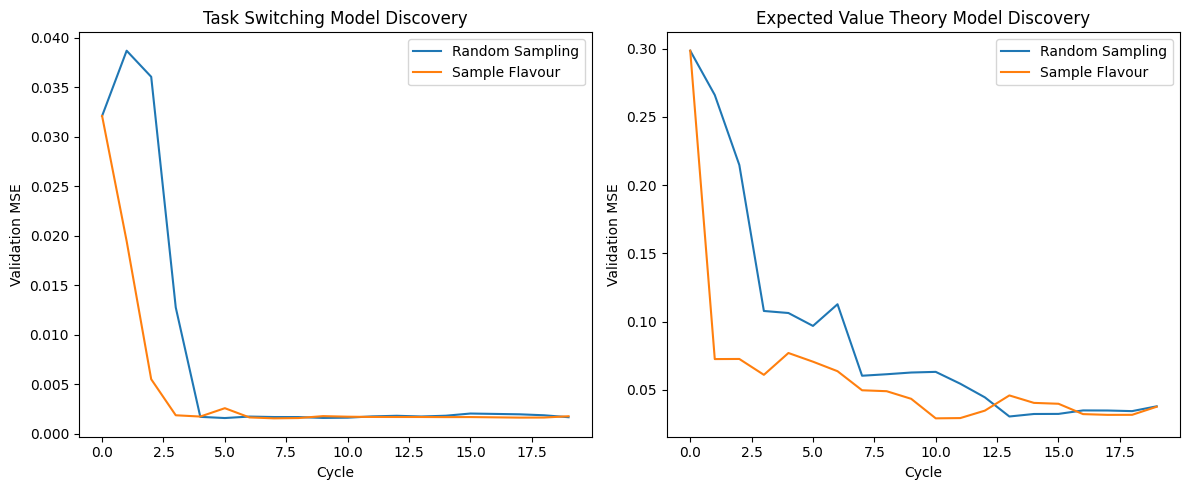

In [14]:

# Ground truth 1: Task Switching (Neuroscience)
experiment_runner = task_switching()
# setting experiment runner and theorist
print("Running simulation for Task Switching...")
benchmark_mse1, custom_mse1, benchmark_state, working_state = run_simulation(num_cycles, num_conditions_per_cycle, num_initial_conditions, bms_epochs, experiment_runner)

# Ground truth 2: Expected Value Theory (Economics)
experiment_runner2 = expected_value_theory()
num_cycles = 20
print("Running simulation for Expected Value Theory...")
benchmark_mse2, custom_mse2, benchmark_state, working_state = run_simulation(num_cycles, num_conditions_per_cycle, num_initial_conditions, bms_epochs, experiment_runner2)

# Ground truth 2: Expected Value Theory (Economics)

# Plot results
plt.figure(figsize=(12,5))

plt.subplot(1, 2, 1)
plt.plot(benchmark_mse1, label='Random Sampling')
plt.plot(custom_mse1, label='Sample Flavour')
plt.title('Task Switching Model Discovery')
plt.xlabel('Cycle')
plt.ylabel('Validation MSE')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(benchmark_mse2, label='Random Sampling')
plt.plot(custom_mse2, label='Sample Flavour')
plt.title('Expected Value Theory Model Discovery')
plt.xlabel('Cycle')
plt.ylabel('Validation MSE')
plt.legend()

plt.tight_layout()
plt.show()